# Chapter 8: Whole Numbers Have Architecture

*Math Class Didn't Show Its Work* by Jason Karpeles

**In this notebook you will** open up whole numbers to see what they are made of: factor pairs, prime factors that never change, how a minus sign and an exponent interact, and how a square root undoes a square.

The code cells are optional reading. You do not need to run anything or follow the code: the results and the pictures are shown right below each cell. If you do want to peek, each code cell redoes the arithmetic one substitution at a time, the way you would on paper.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
%matplotlib inline

# Colors used in every picture
TEAL = "#1f7a7a"
TERRACOTTA = "#c25b3f"
NAVY = "#24344d"
GOLD = "#d9a441"
LIGHT = "#cfd6dd"
INK = "#1d1d1d"

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11})

def fmt(n):
    """Whole number with commas, like 5,084,000."""
    return f"{int(n):,}"

def signed(n):
    """Show a plus sign on positive numbers: +11, -4, 0."""
    return f"+{n}" if n > 0 else str(n)

def factor_pairs(n):
    """Divide by 1, 2, 3, ... and record each partner. Stop when the partners reverse."""
    pairs, k = [], 1
    while k * k <= n:
        if n % k == 0:
            pairs.append((k, n // k))
        k += 1
    return pairs

def prime_factors(n):
    out, p = [], 2
    while n > 1:
        while n % p == 0:
            out.append(p)
            n //= p
        p += 1
    return out

def with_exponents(factors):
    parts = []
    for p in sorted(set(factors)):
        e = factors.count(p)
        parts.append(f"{p}^{e}" if e > 1 else str(p))
    return " x ".join(parts)

## Demonstration 1: Factor pairs as rectangles

**Question in plain words:** How many different rectangles can 36 tiles make, and what happens with 13 tiles, or with 1?

$$36 \div 4 = 9$$

**What the symbols mean:**
- A **factor pair** is two positive whole numbers whose product is the number. Each pair is one rectangle of tiles, using every tile with no gaps.
- A **prime** has exactly two factors, 1 and itself. A **composite** has more than two.
- Searching candidates in order, the partners start to repeat after the square pair, so the list is complete there.

**Predict first:** how many rectangles will 13 tiles make?

In [2]:
def factors_report(n):
    pairs = factor_pairs(n)
    print(f"Number of tiles: {n}")
    for k, partner in pairs:
        print(f"  {n} / {k} = {partner}")
    all_f = sorted({x for pair in pairs for x in pair})
    print("  Factor pairs: " + ", ".join(f"{a} x {b}" for a, b in pairs))
    print("  Positive factors: " + ", ".join(map(str, all_f)))
    print(f"  Number of factors: {len(all_f)}")
    kind = {1: "neither prime nor composite (it has only one factor)",
            2: "prime (exactly two factors, 1 and itself)"}.get(len(all_f), "composite (more than two factors)")
    print(f"  Type: {kind}")
    print()

factors_report(36)
print("Other menu values:\n")
for n in (6, 13, 1):
    factors_report(n)

Number of tiles: 36
  36 / 1 = 36
  36 / 2 = 18
  36 / 3 = 12
  36 / 4 = 9
  36 / 6 = 6
  Factor pairs: 1 x 36, 2 x 18, 3 x 12, 4 x 9, 6 x 6
  Positive factors: 1, 2, 3, 4, 6, 9, 12, 18, 36
  Number of factors: 9
  Type: composite (more than two factors)

Other menu values:

Number of tiles: 6
  6 / 1 = 6
  6 / 2 = 3
  Factor pairs: 1 x 6, 2 x 3
  Positive factors: 1, 2, 3, 6
  Number of factors: 4
  Type: composite (more than two factors)

Number of tiles: 13
  13 / 1 = 13
  Factor pairs: 1 x 13
  Positive factors: 1, 13
  Number of factors: 2
  Type: prime (exactly two factors, 1 and itself)

Number of tiles: 1
  1 / 1 = 1
  Factor pairs: 1 x 1
  Positive factors: 1
  Number of factors: 1
  Type: neither prime nor composite (it has only one factor)



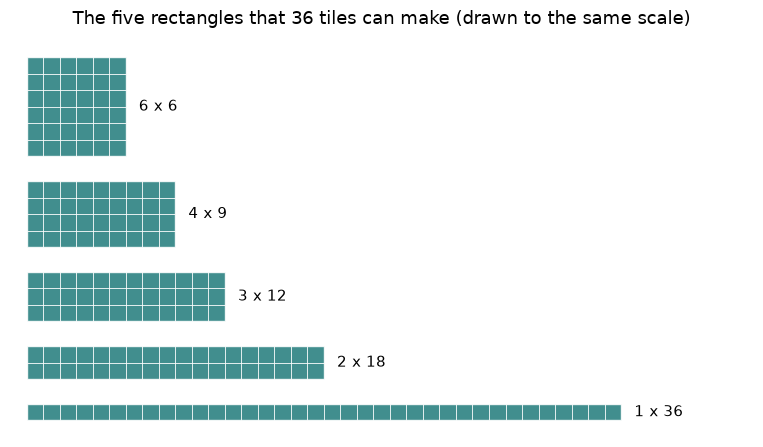

In [3]:
n = 36
pairs = factor_pairs(n)
fig, ax = plt.subplots(figsize=(11, 4.6))
y = 0
for a, b in pairs:
    ax.add_patch(Rectangle((0, y), b, a, facecolor=TEAL, edgecolor="white", alpha=0.85))
    for i in range(1, b):
        ax.vlines(i, y, y + a, color="white", linewidth=0.6)
    for j in range(1, a):
        ax.hlines(y + j, 0, b, color="white", linewidth=0.6)
    ax.text(b + 0.8, y + a / 2, f"{a} x {b}", va="center", fontsize=11)
    y += a + 1.5
ax.set_xlim(-1, 44); ax.set_ylim(-1, y); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("The five rectangles that 36 tiles can make (drawn to the same scale)")
plt.tight_layout(); plt.show()

**What this shows.** Dividing 36 by 1, 2, 3, 4, 6 gives the partners 36, 18, 12, 9, 6, and the search stops once the partners would reverse. So 36 has the pairs 1 x 36, 2 x 18, 3 x 12, 4 x 9, 6 x 6, which is 9 factors in all: more than two, so 36 is composite. 13 tiles make only 1 x 13, so 13 is prime. To list factors, divide by 1, 2, 3 and so on, write each partner, and stop when the partners turn around.

**Where it stops working.** This is for positive whole numbers and positive factors only. 1 is neither prime nor composite because it has one factor; 0 is outside the definitions entirely.

## Demonstration 2: Different trees, same primes

**Question in plain words:** If you start 360 with a different split, do you end with different primes?

$$360 = 2 \times 2 \times 2 \times 3 \times 3 \times 5$$
$$360 = 2^3 \times 3^2 \times 5$$

**What the symbols mean:**
- Each branch splits a number into two factors. An endpoint is **prime** and cannot split further.
- The exponent counts how many times a prime repeats: $2^3 = 2 \times 2 \times 2$.
- The branches change with the first split, but the final inventory never does.

**Predict first:** starting with $360 = 45 \times 8$, how many 2s will appear at the endpoints?

In [4]:
TREES = {
    "36 x 10": {360: (36, 10), 36: (4, 9), 10: (2, 5), 4: (2, 2), 9: (3, 3)},
    "45 x 8":  {360: (45, 8), 45: (9, 5), 9: (3, 3), 8: (2, 4), 4: (2, 2)},
    "18 x 20": {360: (18, 20), 18: (2, 9), 9: (3, 3), 20: (4, 5), 4: (2, 2)},
}

def endpoints(splits, value=360):
    if value not in splits:
        return [value]
    a, b = splits[value]
    return endpoints(splits, a) + endpoints(splits, b)

def tree_report(name):
    splits = TREES[name]
    first, second = splits[360]
    print(f"First split: {first} x {second} = {first * second}")
    for v, (a, b) in splits.items():
        print(f"  {v} = {a} x {b}")
    leaves = endpoints(splits)
    print("  Endpoints in tree order: " + ", ".join(map(str, leaves)))
    s = sorted(leaves)
    print("  Sorted: " + " x ".join(map(str, s)))
    print(f"  With exponents: {with_exponents(s)}")
    twos, threes, fives = s.count(2), s.count(3), s.count(5)
    print(f"  Check: 2 x 2 x 2 = {2**twos}, 3 x 3 = {3**threes}, and {2**twos} x {3**threes} x 5 = {2**twos * 3**threes} x 5 = {2**twos * 3**threes * 5}")
    print()

tree_report("36 x 10")
print("Other menu values:\n")
tree_report("45 x 8")
tree_report("18 x 20")

First split: 36 x 10 = 360
  360 = 36 x 10
  36 = 4 x 9
  10 = 2 x 5
  4 = 2 x 2
  9 = 3 x 3
  Endpoints in tree order: 2, 2, 3, 3, 2, 5
  Sorted: 2 x 2 x 2 x 3 x 3 x 5
  With exponents: 2^3 x 3^2 x 5
  Check: 2 x 2 x 2 = 8, 3 x 3 = 9, and 8 x 9 x 5 = 72 x 5 = 360

Other menu values:

First split: 45 x 8 = 360
  360 = 45 x 8
  45 = 9 x 5
  9 = 3 x 3
  8 = 2 x 4
  4 = 2 x 2
  Endpoints in tree order: 3, 3, 5, 2, 2, 2
  Sorted: 2 x 2 x 2 x 3 x 3 x 5
  With exponents: 2^3 x 3^2 x 5
  Check: 2 x 2 x 2 = 8, 3 x 3 = 9, and 8 x 9 x 5 = 72 x 5 = 360

First split: 18 x 20 = 360
  360 = 18 x 20
  18 = 2 x 9
  9 = 3 x 3
  20 = 4 x 5
  4 = 2 x 2
  Endpoints in tree order: 2, 3, 3, 2, 2, 5
  Sorted: 2 x 2 x 2 x 3 x 3 x 5
  With exponents: 2^3 x 3^2 x 5
  Check: 2 x 2 x 2 = 8, 3 x 3 = 9, and 8 x 9 x 5 = 72 x 5 = 360



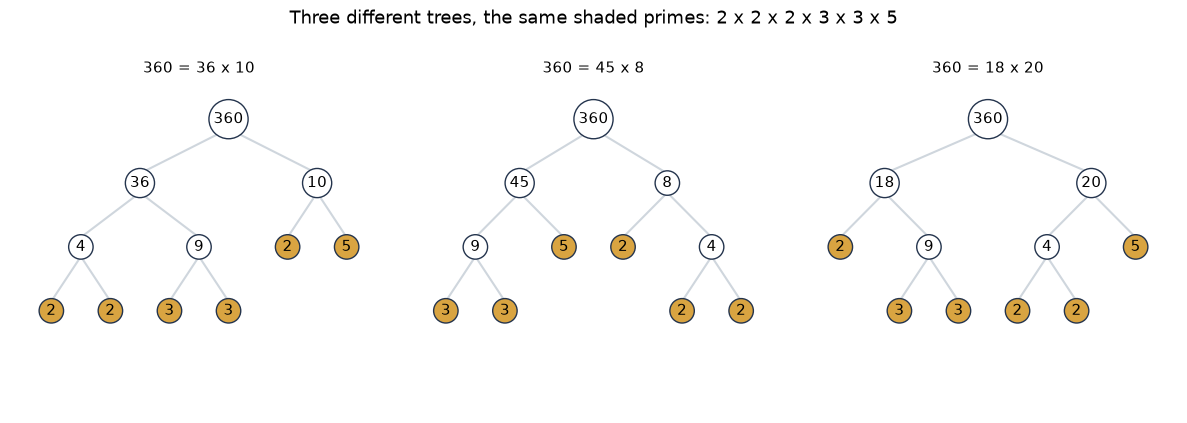

In [5]:
def draw_tree(ax, splits, title):
    positions = {}
    leaf_x = [0]
    def layout(v, depth):
        if v not in splits:
            x = leaf_x[0]; leaf_x[0] += 1
            positions[(v, id(object()))] = None
            return (x, depth, v, [])
        a, b = splits[v]
        ca, cb = layout(a, depth + 1), layout(b, depth + 1)
        return ((ca[0] + cb[0]) / 2, depth, v, [ca, cb])
    root = layout(360, 0)
    def draw(node):
        x, d, v, kids = node
        prime = not kids
        ax.text(x, -d, str(v), ha="center", va="center", fontsize=11,
                bbox=dict(boxstyle="circle,pad=0.3", fc=GOLD if prime else "white", ec=NAVY))
        for k in kids:
            ax.plot([x, k[0]], [-d - 0.15, -k[1] + 0.15], color=LIGHT, zorder=0)
            draw(k)
    draw(root)
    ax.set_xlim(-0.7, leaf_x[0] - 0.3); ax.set_ylim(-4.6, 0.6); ax.axis("off")
    ax.set_title(title, fontsize=11)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
for ax, name in zip(axes, TREES):
    draw_tree(ax, TREES[name], f"360 = {name}")
plt.suptitle("Three different trees, the same shaded primes: 2 x 2 x 2 x 3 x 3 x 5", y=1.0)
plt.tight_layout(); plt.show()

**What this shows.** For the split $36 \times 10 = 360$, the endpoints are 2, 2, 3, 3, 2, 5. Sorted: $2 \times 2 \times 2 \times 3 \times 3 \times 5$. Check: $2 \times 2 \times 2 = 8$, $3 \times 3 = 9$, and $8 \times 9 \times 5 = 72 \times 5 = 360$. Three 2s, two 3s and one 5, whichever split comes first. So start a factor tree with whatever split you see first, then multiply the endpoints back together to check the inventory.

**Where it stops working.** This is for a positive whole number greater than 1. The order of factors does not matter. Stopping at a composite endpoint such as 4 leaves the factorization unfinished.

## Demonstration 3: A negative base or a minus outside

**Question in plain words:** Why is $(-3)^2$ equal to $9$ while $-3^2$ is $-9$?

$$(-3)^2 = (-3)(-3) = 9$$
$$-(3 \times 3) = -9$$
$$(-2)^3 = (-2)(-2)(-2) = 4(-2) = -8$$

**What the symbols mean:**
- The **base** is what gets repeated; the **exponent** counts the copies.
- Parentheses around $-3$ make $-3$ the base. Without them, only $3$ is the base and the minus is applied last.
- A negative base flips the sign with every factor, so even counts end positive. A minus outside waits until the power is done.

**Predict first:** with base 3 and exponent 3, will $(-3)^3$ and $-3^3$ agree?

In [6]:
def power(b, inside, n):
    if inside:
        base = -b
        label = f"(-{b})^{n}"
        run, prod, steps = [], 1, []
        for k in range(n):
            prod *= base
            run.append(prod)
        chain = " x ".join(f"({base})" for _ in range(n))
        print(f"{label} = {chain} = {run[-1]}")
        print(f"  Base is {base}. Running products after each factor: {run}")
        other = -(b ** n)
        print(f"  The other form: -{b}^{n} = -({' x '.join([str(b)] * n)}) = {other}")
        val = run[-1]
    else:
        label = f"-{b}^{n}"
        pw = b ** n
        print(f"{label} = -({' x '.join([str(b)] * n)}) = {-pw}")
        print(f"  Base is {b}. The power is done first: {b}^{n} = {pw}. Then the minus is applied.")
        other = (-b) ** n
        print(f"  The other form: (-{b})^{n} = {other}")
        val = -pw
    print("  Both forms agree." if val == other else "  The two forms give different values.")
    print()

power(2, True, 3)
print("Other menu values:\n")
power(2, False, 3)
power(2, True, 2)
power(2, False, 2)
power(3, True, 2)
power(3, False, 2)
power(3, True, 3)
power(3, False, 3)

(-2)^3 = (-2) x (-2) x (-2) = -8
  Base is -2. Running products after each factor: [-2, 4, -8]
  The other form: -2^3 = -(2 x 2 x 2) = -8
  Both forms agree.

Other menu values:

-2^3 = -(2 x 2 x 2) = -8
  Base is 2. The power is done first: 2^3 = 8. Then the minus is applied.
  The other form: (-2)^3 = -8
  Both forms agree.

(-2)^2 = (-2) x (-2) = 4
  Base is -2. Running products after each factor: [-2, 4]
  The other form: -2^2 = -(2 x 2) = -4
  The two forms give different values.

-2^2 = -(2 x 2) = -4
  Base is 2. The power is done first: 2^2 = 4. Then the minus is applied.
  The other form: (-2)^2 = 4
  The two forms give different values.

(-3)^2 = (-3) x (-3) = 9
  Base is -3. Running products after each factor: [-3, 9]
  The other form: -3^2 = -(3 x 3) = -9
  The two forms give different values.

-3^2 = -(3 x 3) = -9
  Base is 3. The power is done first: 3^2 = 9. Then the minus is applied.
  The other form: (-3)^2 = 9
  The two forms give different values.

(-3)^3 = (-3) x (-3

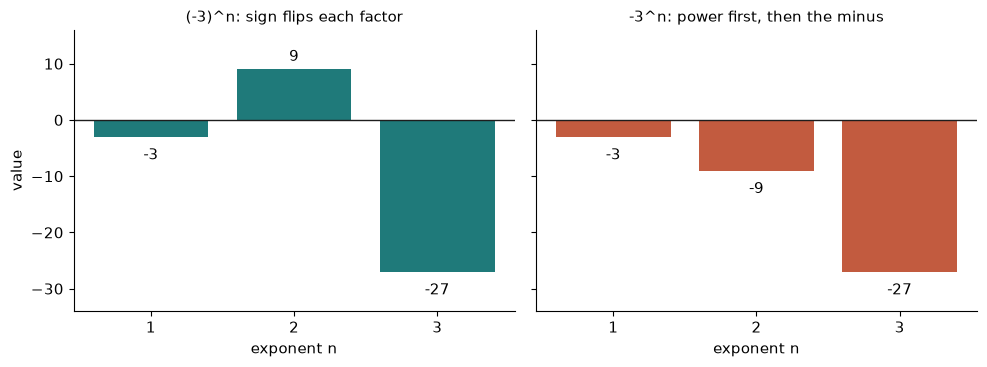

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
b, n = 3, 3
inside = [(-b) ** k for k in range(1, n + 1)]
outside = [-(b ** k) for k in range(1, n + 1)]
for ax, vals, title, col in ((axes[0], inside, "(-3)^n: sign flips each factor", TEAL),
                             (axes[1], outside, "-3^n: power first, then the minus", TERRACOTTA)):
    ax.bar(range(1, n + 1), vals, color=col)
    for k, v in zip(range(1, n + 1), vals):
        ax.text(k, v + (1.5 if v >= 0 else -4), str(v), ha="center")
    ax.axhline(0, color=INK, linewidth=1)
    ax.set_ylim(-34, 16)
    ax.set_xticks(range(1, n + 1)); ax.set_xlabel("exponent n")
    ax.set_title(title, fontsize=11)
axes[0].set_ylabel("value")
plt.tight_layout(); plt.show()

**What this shows.** For the default, $(-2)^3 = (-2)(-2)(-2) = 4(-2) = -8$. The form $-2^3$ is also $-8$: with an odd number of factors the values agree, but for different reasons. With an even exponent they split apart, as in $(-3)^2 = 9$ against $-3^2 = -9$. Before calculating a power, circle the complete base, and keep any minus sign outside the circle separate until the end.

**Where it stops working.** This uses positive whole numbers 2 and 3 as bases and positive whole-number exponents. Powers are done before the outside minus, as in the chapter's order of operations.

## Demonstration 4: A square root reverses a square

**Question in plain words:** Which nonnegative number squares to 144, and how do its prime factors show it?

$$\sqrt{144} = 12$$
$$144 = 2^4 \times 3^2 = (2^2 \times 3)^2 = 12^2$$

**What the symbols mean:**
- The root symbol names the **principal square root**: the nonnegative number whose square is the given number.
- A perfect square splits its prime factors into matching pairs. One from each pair gives the side of the square. An unpaired prime leaves tiles over.

**Predict first:** will 50 tiles make a complete square?

In [8]:
def sqrt_report(n):
    f = prime_factors(n)
    print(f"Number: {n}")
    print(f"  Prime factors: {n} = {' x '.join(map(str, f))} = {with_exponents(f)}")
    unpaired = [p for p in sorted(set(f)) if f.count(p) % 2 == 1]
    if not unpaired:
        half = [p for p in sorted(set(f)) for _ in range(f.count(p) // 2)]
        root = int(np.prod(half))
        print("  Unpaired primes: none")
        print(f"  One from each pair: {' x '.join(map(str, half))} = {root}")
        print(f"  Principal square root: {root}")
        print(f"  Squaring check: {root} x {root} = {root * root}")
    else:
        lo = int(n ** 0.5)
        print("  Unpaired primes: " + ", ".join(map(str, unpaired)))
        print(f"  Not a perfect square: {lo} x {lo} = {lo * lo} and {lo + 1} x {lo + 1} = {(lo + 1) ** 2}, so the root is between {lo} and {lo + 1}")
    print()

sqrt_report(144)
print("Other menu values:\n")
for n in (36, 81, 50):
    sqrt_report(n)

Number: 144
  Prime factors: 144 = 2 x 2 x 2 x 2 x 3 x 3 = 2^4 x 3^2
  Unpaired primes: none
  One from each pair: 2 x 2 x 3 = 12
  Principal square root: 12
  Squaring check: 12 x 12 = 144

Other menu values:

Number: 36
  Prime factors: 36 = 2 x 2 x 3 x 3 = 2^2 x 3^2
  Unpaired primes: none
  One from each pair: 2 x 3 = 6
  Principal square root: 6
  Squaring check: 6 x 6 = 36

Number: 81
  Prime factors: 81 = 3 x 3 x 3 x 3 = 3^4
  Unpaired primes: none
  One from each pair: 3 x 3 = 9
  Principal square root: 9
  Squaring check: 9 x 9 = 81

Number: 50
  Prime factors: 50 = 2 x 5 x 5 = 2 x 5^2
  Unpaired primes: 2
  Not a perfect square: 7 x 7 = 49 and 8 x 8 = 64, so the root is between 7 and 8



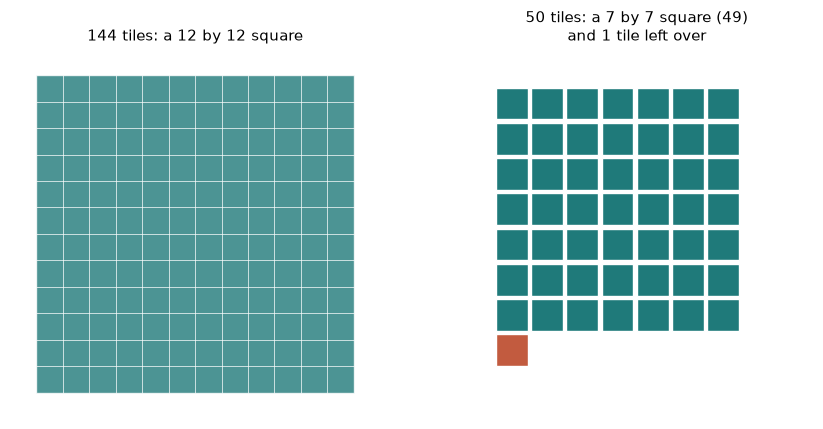

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.4))
ax = axes[0]
ax.add_patch(Rectangle((0, 0), 12, 12, facecolor=TEAL, alpha=0.8, edgecolor="white"))
for i in range(1, 12):
    ax.vlines(i, 0, 12, color="white", linewidth=0.5)
    ax.hlines(i, 0, 12, color="white", linewidth=0.5)
ax.set_xlim(-1, 13); ax.set_ylim(-1, 13); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("144 tiles: a 12 by 12 square", fontsize=11)

ax = axes[1]
for k in range(50):
    r, c = divmod(k, 7)
    full = r < 7
    ax.add_patch(Rectangle((c, 6 - r), 0.9, 0.9, facecolor=TEAL if k < 49 else TERRACOTTA, edgecolor="white"))
ax.set_xlim(-1, 9); ax.set_ylim(-2.5, 8); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("50 tiles: a 7 by 7 square (49)\nand 1 tile left over", fontsize=11)
plt.tight_layout(); plt.show()

**What this shows.** $144 = 2^4 \times 3^2$. Every prime factor is paired, and one from each pair gives $2 \times 2 \times 3 = 12$. Check: $12 \times 12 = 144$. The number $-12$ also squares to 144, but the root symbol names only the nonnegative one. To check a proposed square root, square it and confirm the root is not negative.

**Where it stops working.** This is for whole numbers and perfect squares when you want whole-number roots. When solving $x^2 = 144$, both 12 and $-12$ work, but the root symbol by itself names only 12.

## Practice

**1.** List the factor pairs of 24. Is 24 prime or composite?

<details><summary>Show answer</summary>

Divide in order: 24 / 1 = 24, 24 / 2 = 12, 24 / 3 = 8, 24 / 4 = 6. The next candidate, 5, does not divide 24, and 6 would repeat the pair 4 x 6, so stop.
Pairs: 1 x 24, 2 x 12, 3 x 8, 4 x 6. That is 8 factors, more than two, so 24 is composite.

</details>

**2.** Using $84 = 2 \times 42$, what is the prime factorization of 84?

<details><summary>Show answer</summary>

84 = 2 x 42 = 2 x 2 x 21 = 2 x 2 x 3 x 7 = 2^2 x 3 x 7.
Check: 4 x 21 = 84.

</details>

**3.** What are $(-2)^4$ and $-2^4$?

<details><summary>Show answer</summary>

(-2)^4 = (-2)(-2)(-2)(-2) = 4 x 4 = 16.
-2^4 = -(2 x 2 x 2 x 2) = -16.

</details>

**4.** What is the principal square root of 196, and what are its paired prime factors?

<details><summary>Show answer</summary>

196 = 2^2 x 7^2 = (2 x 7)^2, so the principal square root is 2 x 7 = 14.
Check: 14 x 14 = 196.

</details>